In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [4]:
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [5]:
data = df[['Age','Positive Feedback Count']]

In [6]:
data.head()

,Age,Positive Feedback Count
0,33,0
1,34,4
2,60,0
3,50,0
4,47,6


Clean the data

In [7]:
data = data.dropna()

In [8]:
data = data[data['Age']>0]
data = data[data['Positive Feedback Count']>=0]

data.head()

,Age,Positive Feedback Count
0,33,0
1,34,4
2,60,0
3,50,0
4,47,6


Visualize age and positive feedback

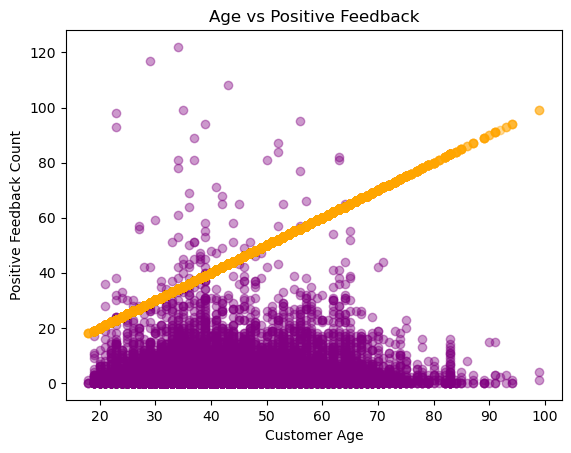

In [9]:
plt.scatter(data['Age'],data['Positive Feedback Count'],label='positive feedback',color='purple',alpha=0.4)
plt.scatter(data['Age'],data['Age'],color='orange',label='age',alpha=0.4)
plt.title("Age vs Positive Feedback")
plt.xlabel("Customer Age")
plt.ylabel("Positive Feedback Count")
plt.show()

In [10]:
x = data[['Age']]
y = data[['Positive Feedback Count']]

In [11]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)

Apply Linear Regression

In [12]:
lr = LinearRegression()
lr.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [13]:
y_pred = lr.predict(x_test)

In [14]:
print("Linear Regression R2:", r2_score(y_test, y_pred))
print("Linear Regression MSE:", mean_squared_error(y_test, y_pred))

Linear Regression R2: 0.002382643077748048
Linear Regression MSE: 29.57842705741395


Apply Polynomial Regression

In [15]:
poly = PolynomialFeatures(degree=2)

x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)

In [16]:
poly_model = LinearRegression()
poly_model.fit(x_train_poly,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [17]:
poly_pred = poly_model.predict(x_test_poly)

In [18]:
print("Polynomial Regression R2:", r2_score(y_test, poly_pred))
print("Polynomial Regression MSE:", mean_squared_error(y_test, poly_pred))

Polynomial Regression R2: 0.002595888027260629
Polynomial Regression MSE: 29.57210454293407


Test multiple polynomial degrees

In [19]:
results = []
for degree in [2,3,4]:
    poly = PolynomialFeatures(degree=degree)

    x_train_poly = poly.fit_transform(x_train)
    x_test_poly = poly.transform(x_test)

    model = LinearRegression()
    model.fit(x_train_poly,y_train)

    pred = model.predict(x_test_poly)

    results.append({
        'Degree' : degree,
        'R2 Score' : r2_score(y_test,pred),
        'MSE' : mean_squared_error(y_test,pred)
    })

results_df = pd.DataFrame(results)

results_df

,Degree,R2 Score,MSE
0,2,0.002596,29.572105
1,3,0.002680,29.569610
2,4,0.002679,29.569639


Visualize polynomial regression

In [20]:
poly = PolynomialFeatures(degree=2)

x_poly = poly.fit_transform(x)

model = LinearRegression()
model.fit(x_poly, y)

y_pred = model.predict(x_poly)

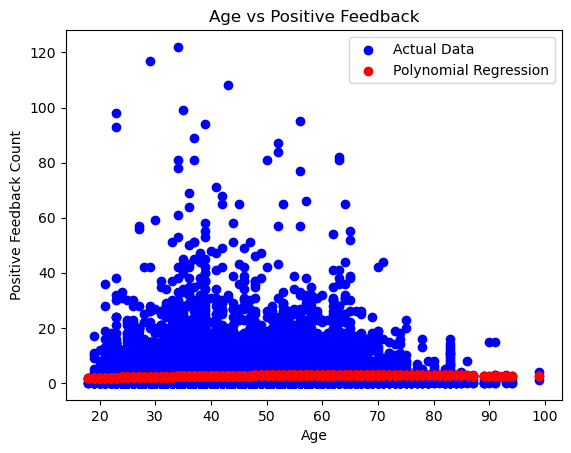

In [21]:
plt.scatter(x,y,color='blue',label='Actual Data')
plt.scatter(x,y_pred,color='red',label='Polynomial Regression')
plt.title("Age vs Positive Feedback")
plt.xlabel("Age")
plt.ylabel("Positive Feedback Count")
plt.legend()
plt.show()

Test different transformations

In [22]:
data['log_feedback'] = np.log1p(data['Positive Feedback Count'])

In [23]:
data.head()

,Age,Positive Feedback Count,log_feedback
0,33,0,0.000000
1,34,4,1.609438
2,60,0,0.000000
3,50,0,0.000000
4,47,6,1.945910


In [24]:
x = data[['Age']]
y = data[['Positive Feedback Count']]

In [25]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)

In [26]:
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)

In [27]:
poly = PolynomialFeatures(degree=2)
poly.fit(x_train_poly,y_train)

,degree,2
,interaction_only,False
,include_bias,True
,order,'C'


In [28]:
model = LinearRegression()
model.fit(x_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
pred = model.predict(x_test_poly)
print("Log Transformation R2:", r2_score(y_test, pred))
print("Log Transformation MSE:", mean_squared_error(y_test, pred))

Log Transformation R2: 0.002595888027260629
Log Transformation MSE: 29.57210454293407


Analyze different customer demographics

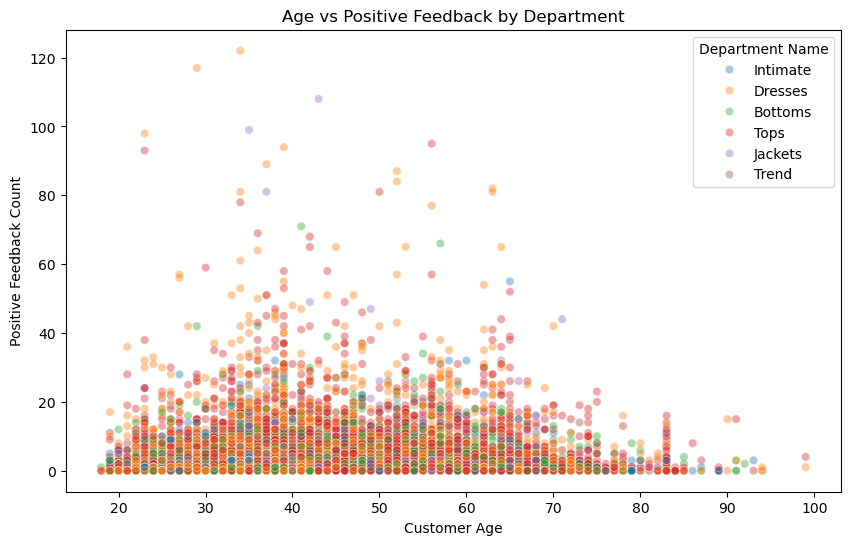

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='Positive Feedback Count',
    hue='Department Name',
    alpha=0.4
)

plt.title("Age vs Positive Feedback by Department")
plt.xlabel("Customer Age")
plt.ylabel("Positive Feedback Count")
plt.show()

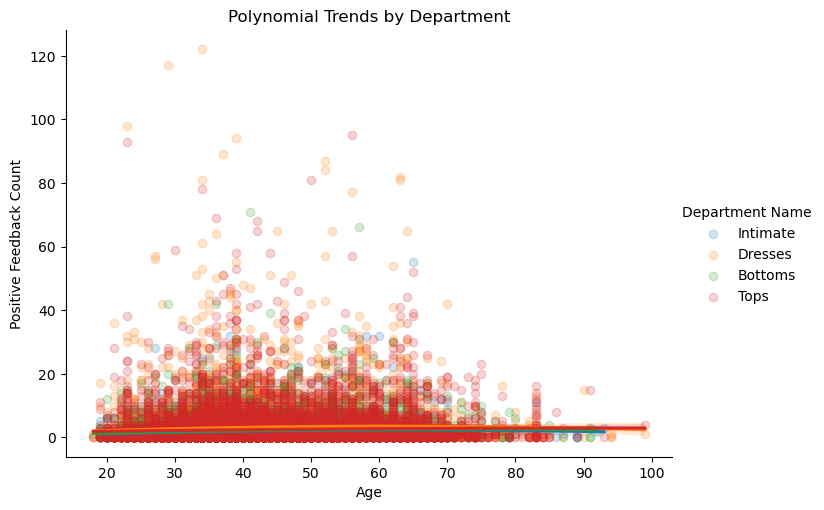

In [31]:
top_departments = df['Department Name'].value_counts().head(4).index

subset = df[df['Department Name'].isin(top_departments)]

sns.lmplot(
    data=subset,
    x='Age',
    y='Positive Feedback Count',
    hue='Department Name',
    order=2,
    scatter_kws={'alpha': 0.2},
    height=5,
    aspect=1.4
)

plt.title("Polynomial Trends by Department")
plt.show()

Segment customers by age

In [32]:
df['age_group'] = pd.cut(
    df['Age'],
    bins=[0, 25, 40, 100],
    labels=['Young', 'Adult', 'Older Adult'],
    include_lowest=True
)

age_summary = df.groupby(
    'age_group', observed=False
)['Positive Feedback Count'].mean()

print(age_summary)

age_group
Young          2.094031
Adult          2.371597
Older Adult    2.714776
Name: Positive Feedback Count, dtype: float64


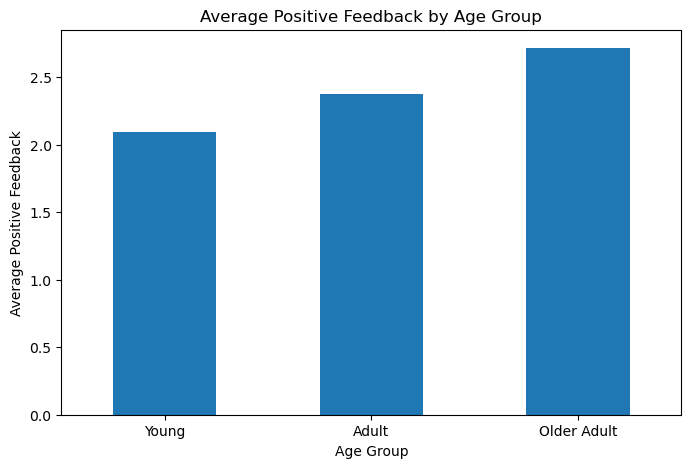

In [33]:
age_summary.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Average Positive Feedback by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Positive Feedback")
plt.xticks(rotation=0)
plt.show()